# Auto insurance pricing: GLM champion vs gradient-boosted challenger

Walkthrough notebook. Runs the whole project on the public **freMTPL2** motor portfolio (678k policies) and shows the results.

**In Google Colab:** Runtime → Run all. The first cell clones the repo; everything else runs in about 3 minutes. No accounts, keys or data access requests are needed.

In [1]:
import os
if not os.path.exists("run_all.py"):          # in Colab: fetch the project
    !git clone -q https://github.com/dorcas-okaidjah/auto-insurance-pricing.git
    %cd auto-insurance-pricing
!pip install -q -r requirements.txt

## 1. Check the code on synthetic data (no download, ~30 s)

In [2]:
!python -m tests.smoke_test 2>&1 | tail -2


SMOKE TEST PASSED


## 2. Download and inspect the real data
Public data from the CASdatasets R package (falls back to the OpenML mirror).

In [3]:
!python -m src.data --download
!python -m src.data --inspect

downloading https://raw.githubusercontent.com/dutangc/CASdatasets/master/data/freMTPL2freq.rda


downloading https://raw.githubusercontent.com/dutangc/CASdatasets/master/data/freMTPL2sev.rda


saved 677,991 policies and 26,444 claims to /home/claude/auto-insurance-pricing/data


  dropped 8 policies with > 4 claims



policies: 677,983   claims: 26,373   exposure: 358,341 policy-years
claim frequency: 0.0736 per year
mean claim: EUR 2,265   median: EUR 1,172   max: EUR 4,075,401

claim count distribution:
ClaimNb
0    653047
1     23571
2      1298
3        62
4         5

numeric features:


               count     mean      std   min    25%     50%      75%      max
VehPower    677983.0     6.45     2.05   4.0   5.00    6.00     7.00     15.0
VehAge      677983.0     7.04     5.67   0.0   2.00    6.00    11.00    100.0
DrivAge     677983.0    45.50    14.14  18.0  34.00   44.00    55.00    100.0
BonusMalus  677983.0    59.76    15.64  50.0  50.00   50.00    64.00    230.0
Density     677983.0  1792.41  3958.59   1.0  92.00  393.00  1658.00  27000.0
Exposure    677983.0     0.53     0.36   0.0   0.18    0.49     0.99      1.0

missing values: 0


## 3. Fit both models, evaluate, build the business case

In [4]:
!python run_all.py

1/6 loading data


  dropped 8 policies with > 4 claims


    train 508,418 / test 169,565 policies; large-loss cap EUR 31,241, load 1.347
2/6 fitting GLM (champion)


3/6 fitting GBM (challenger)


4/6 evaluating on the test set


5/6 explaining the models and building the business case


6/6 writing charts, tables and the summary


done in 82.3s -> /home/claude/auto-insurance-pricing/reports/summary.md


## 4. Results

In [5]:
from IPython.display import Markdown, Image, display
display(Markdown(open("reports/summary.md").read()))

# Results summary

Data: 677,983 motor policies, 358,341 policy-years, 26,373 claims. Train 508,418 / test 169,565 (random split). Individual claims capped at EUR 31,241 (the 99.5% quantile); the excess is spread back as a 1.347x load. Test-set metrics use capped claims x load, so a single very large claim cannot decide a segment's result.

## Model accuracy (test set)

| Metric | GLM (champion) | GBM (challenger) | Better |
|---|---|---|---|
| Poisson deviance, frequency | 0.4559 | 0.4498 | lower |
| Gamma deviance, severity | 1.1820 | 1.1818 | lower |
| Gini, frequency | 0.2913 | 0.3172 | higher |
| Gini, pure premium | 0.3196 | 0.3453 | higher |
| Predicted / actual losses (capped + load) | 0.9641 | 0.9658 | closer to 1 |
| Predicted / actual losses (raw) | 0.9458 | 0.9475 | closer to 1 |

Gini gain from GBM: **+0.0258** (95% bootstrap interval +0.0135 to +0.0371).

## Business case

Premium = expected loss / 70% target loss ratio. A customer switches insurer when the rival quotes at least 5% less. Losses are the test policies' own claims (capped + load).

| Scenario | Challenger wins | Challenger loss ratio | Incumbent loss ratio |
|---|---|---|---|
| We price with GBM, rival uses GLM | 45.4% | **73.8%** | 86.7% |
| We price with GLM, rival uses GBM | 37.1% | 94.1% | **73.1%** |
| We price with capped GBM (+/-15%), rival uses GLM | 45.4% | 66.9% | 86.7% |

Switching the existing book from GLM to GBM prices: 33.7% of customers move less than 10%; 27.0% move more than 25%. Capping year-one changes at +/-15% keeps 59.6% of the Gini gain.

## Actual vs expected by driver age (test set)

| Driver age | GLM A/E | GBM A/E |
|---|---|---|
| 18-24 | 1.132 | 1.124 |
| 25-39 | 0.976 | 0.987 |
| 40-59 | 1.023 | 1.014 |
| 60+ | 1.146 | 1.141 |

Charts: `lorenz_curve.png`, `lift_by_decile.png`, `double_lift.png`, `partial_dependence.png`, `feature_importance.png`, `dislocation.png`.


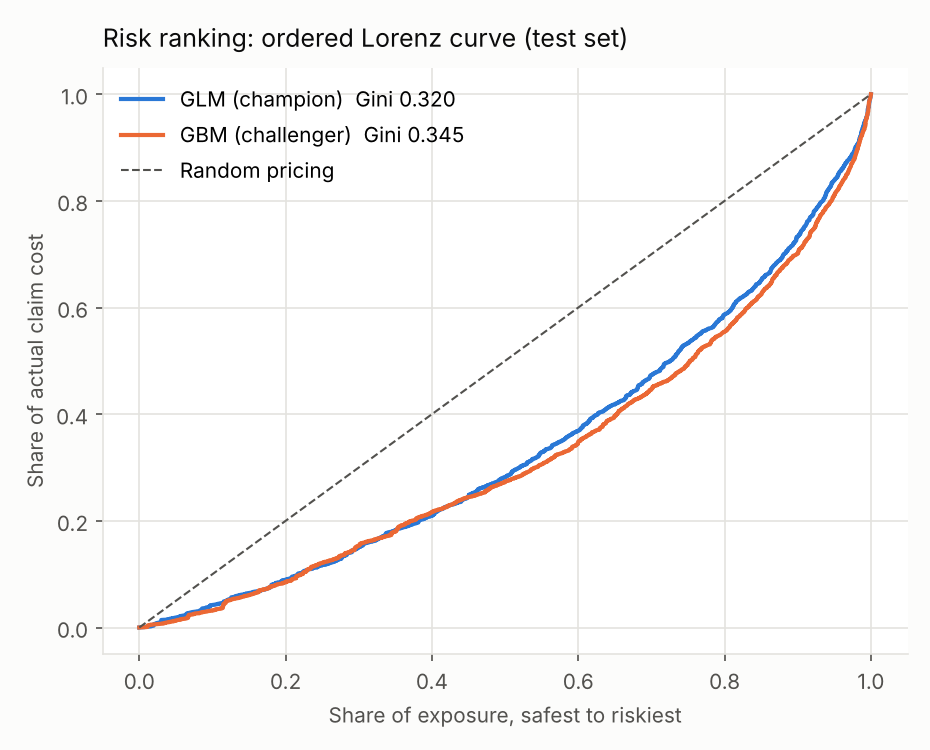

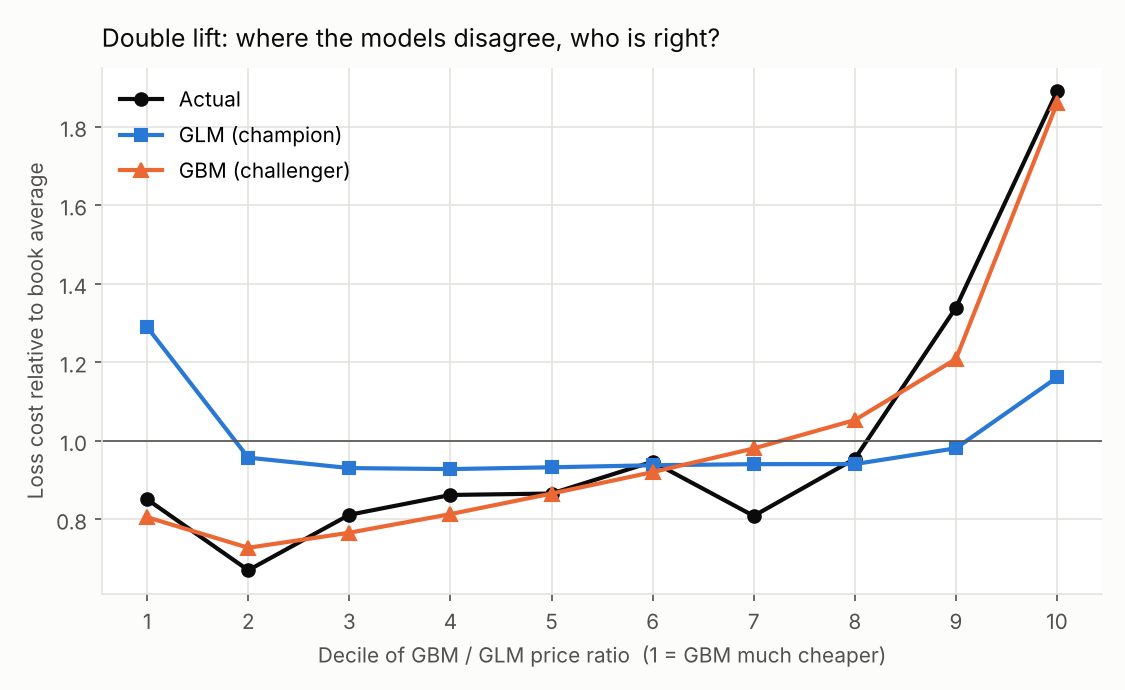

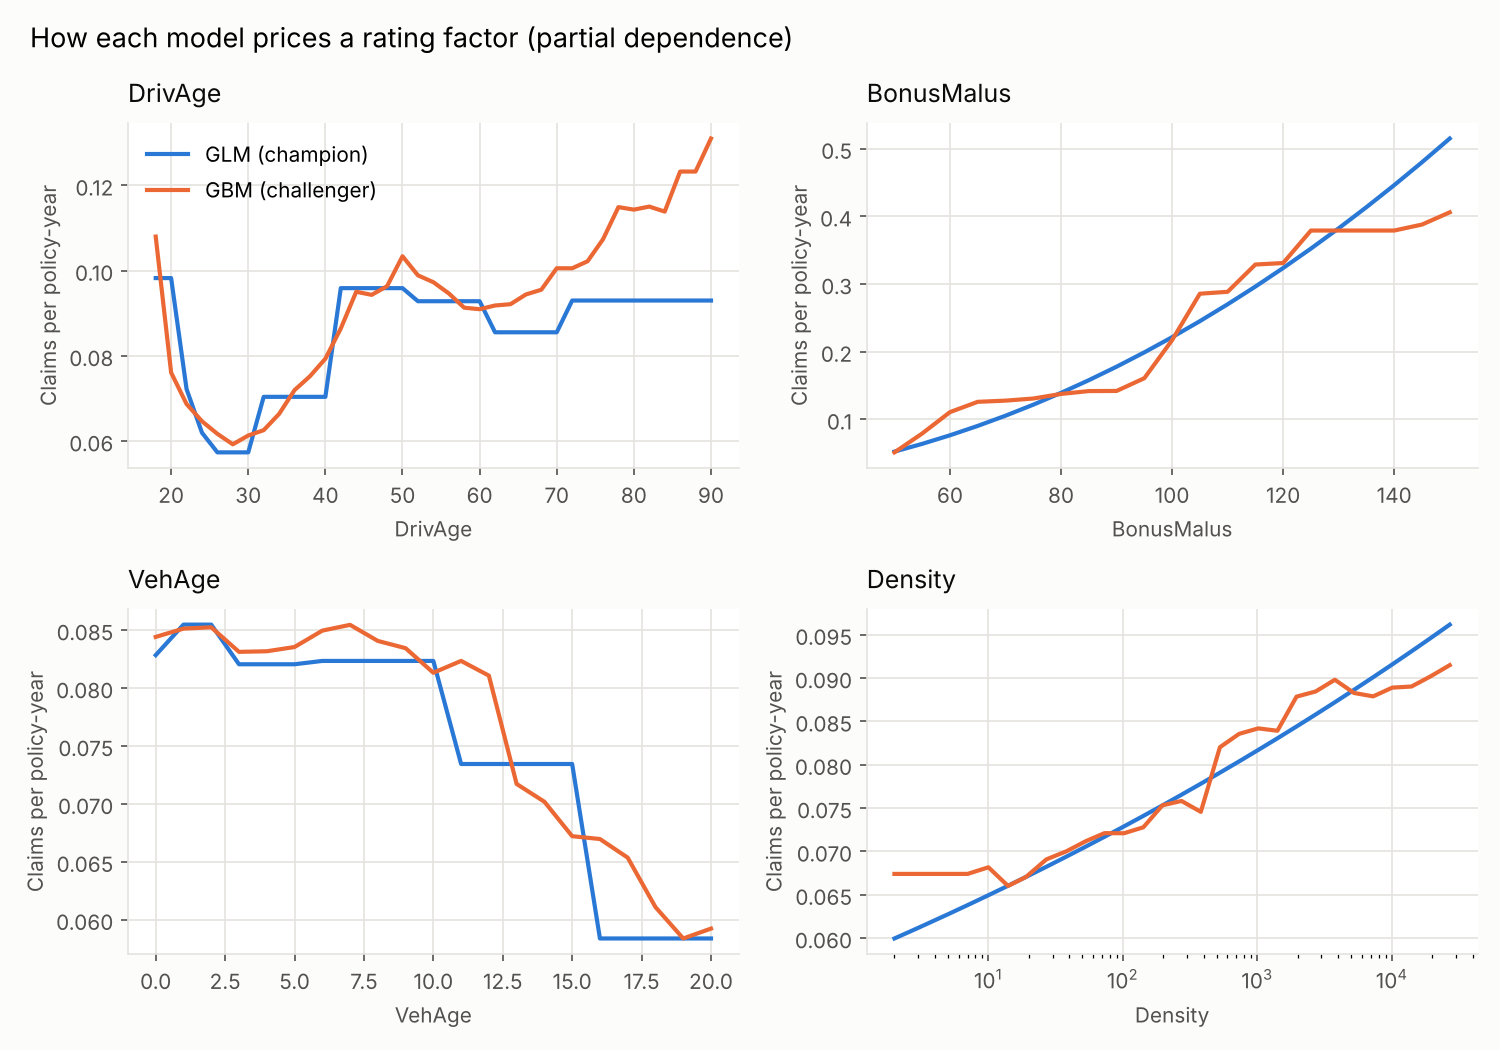

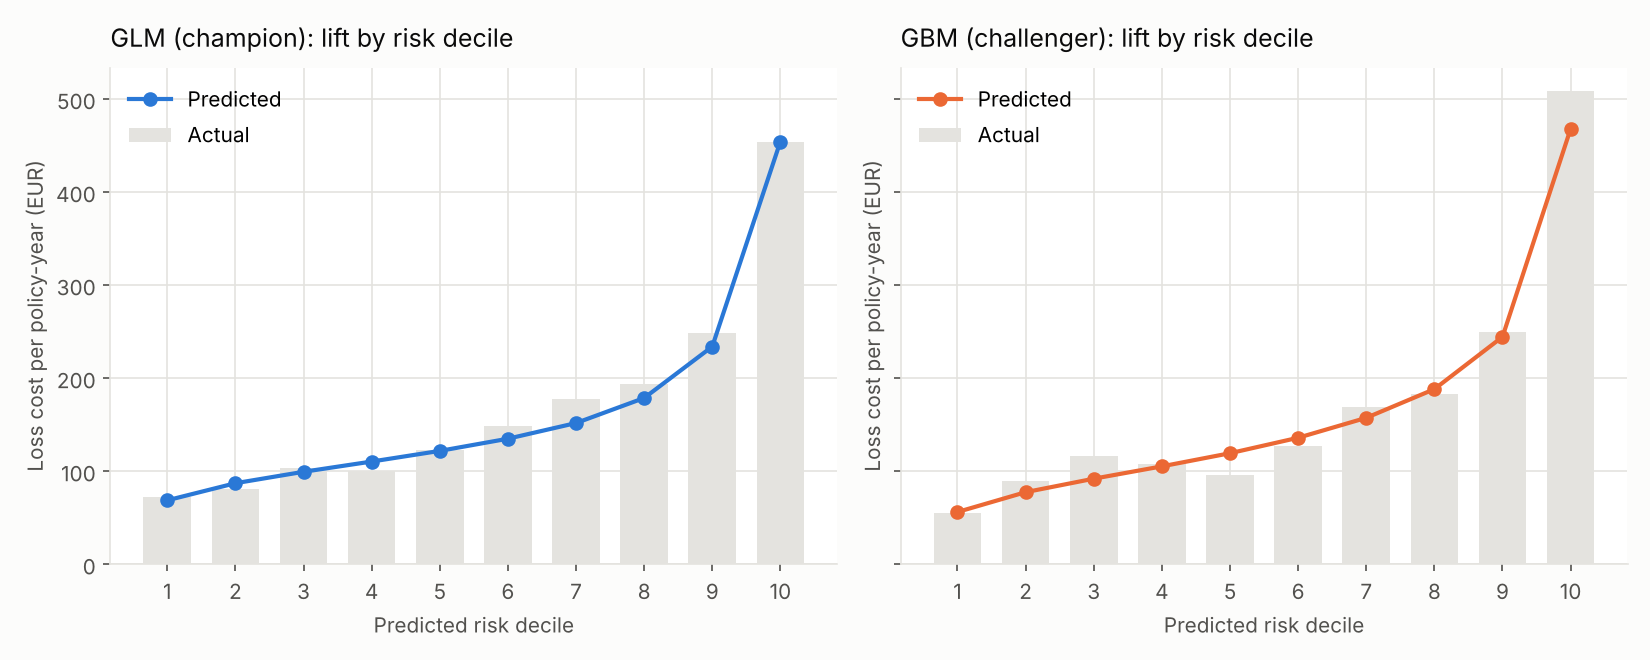

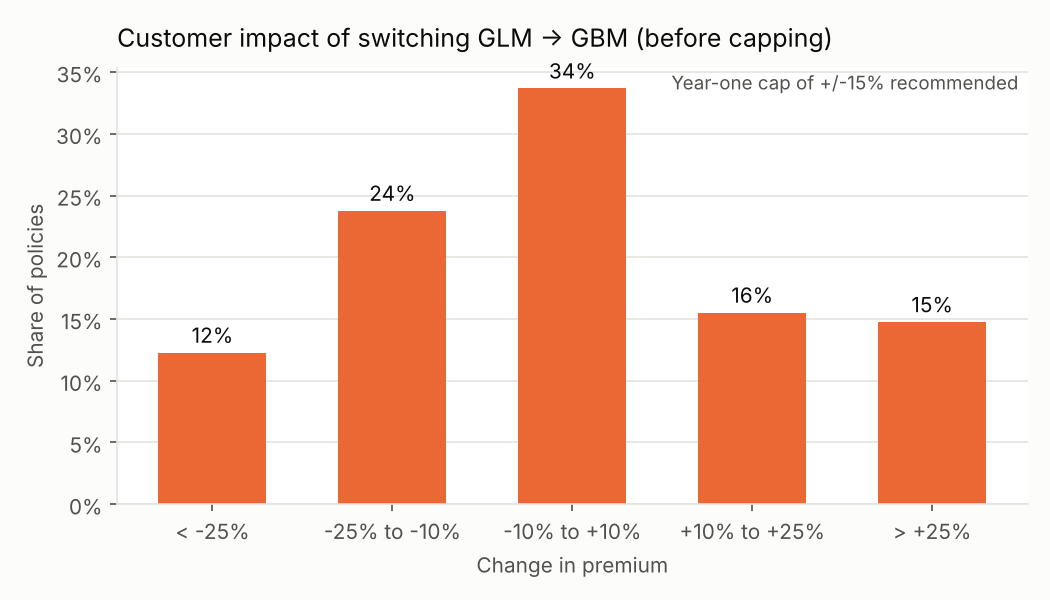

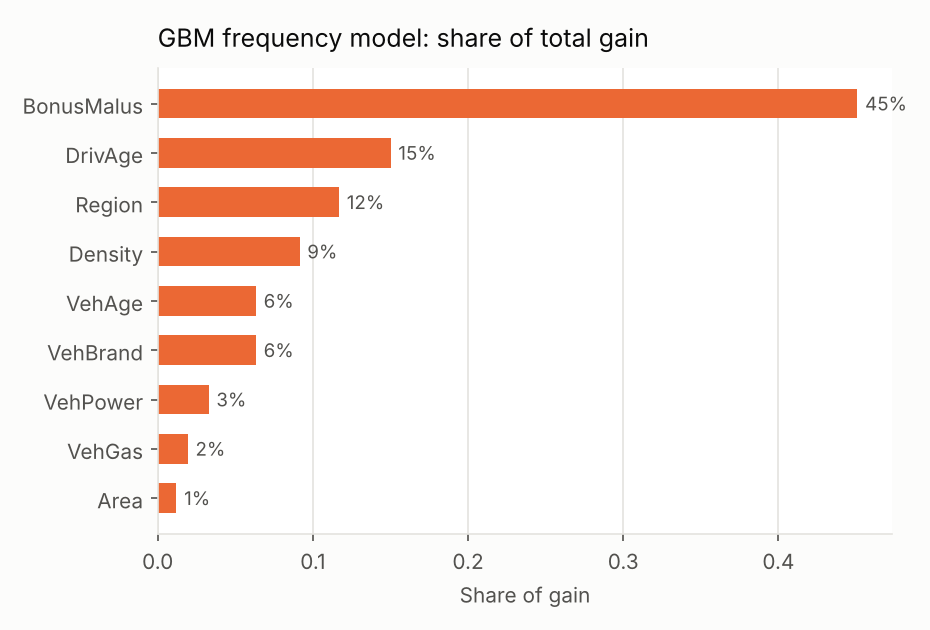

In [6]:
for f in ["lorenz_curve", "double_lift", "partial_dependence", "lift_by_decile",
          "dislocation", "feature_importance"]:
    display(Image(f"reports/{f}.png", width=760))

## 5. The filed-style GLM rating table (frequency relativities)

In [7]:
import pandas as pd
t = pd.read_csv("reports/glm_rating_table.csv")
t[t.factor.isin(["DrivAgeBand", "VehAgeBand", "Area"])]

,factor,level,exposure,relativity
0,Area,A,46491,0.957
1,Area,B,32175,0.982
2,Area,C,78285,1.000
3,Area,D,57950,1.059
4,Area,E,47637,1.072
5,Area,F,6144,1.000
6,DrivAgeBand,"(17, 20]",1954,1.025
7,DrivAgeBand,"(20, 22]",3030,0.753
8,DrivAgeBand,"(22, 25]",7174,0.646
9,DrivAgeBand,"(25, 30]",21798,0.598


## 6. Quote individual policies
Both models' price, the capped year-one price, and what drives the GBM price.

In [8]:
!python -m src.quote --driv-age 19 --bonus-malus 90 --veh-age 2 --density 5000 --area E


Policy: {'VehPower': 6, 'VehAge': 2, 'DrivAge': 19, 'BonusMalus': 90, 'VehBrand': 'B12', 'VehGas': 'Regular', 'Area': 'E', 'Density': 5000, 'Region': 'Centre'}

                               GLM         GBM
frequency                   0.1918      0.1101
severity                 EUR 2,652   EUR 2,318
pure premium               EUR 685     EUR 349
premium                    EUR 979     EUR 498

Proposed year-one premium (GBM, capped at +/-15% vs GLM): EUR 832

What moves this price (GBM, vs a typical policy):
  BonusMalus=90                +162%
  Area=E                       +8%
  Density=5000                 +7%
  DrivAge=19                   +6%
  VehAge=2                     +1%


In [9]:
!python -m src.quote --driv-age 44 --bonus-malus 90


Policy: {'VehPower': 6, 'VehAge': 6, 'DrivAge': 44, 'BonusMalus': 90, 'VehBrand': 'B12', 'VehGas': 'Regular', 'Area': 'C', 'Density': 393, 'Region': 'Centre'}

                               GLM         GBM
frequency                   0.1482      0.1287
severity                 EUR 1,789   EUR 1,706
pure premium               EUR 357     EUR 300
premium                    EUR 511     EUR 429

Proposed year-one premium (GBM, capped at +/-15% vs GLM): EUR 434

What moves this price (GBM, vs a typical policy):
  BonusMalus=90                +162%
